In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

In [3]:
def eigsort(A):
    eigvals, U = np.linalg.eig(A)
    # sort eigenvalues in descending order
    order = np.argsort(eigvals)[::-1]
    eigvals = eigvals[order]
    # re-arrange the eigenvectors
    U = U[:, order]
    return U, eigvals

In [4]:
def pca_classic(X, M):
    # Για κάθε στήλη του πίνακα X υπολογίστε το μέσο όρο
    mu = X.mean(axis=0).reshape((1, -1))

    # Αφαιρέστε το μέσο όρο από τον πίνακα (Centering)
    normalized_X = (X - mu)

    # Υπολογίστε το Covariance matrix (Σημείωση: Εδώ διαιρεί με N, η np.cov διαιρεί με N-1)
    S = (1 / X.shape[0]) * normalized_X.T.dot(normalized_X)

    # Υπολογίστε τα ιδιοδιανύσματα και τις ιδιοτιμές
    eigvectors, eigvals = eigsort(S)

    # Κρατήστε στον πίνακα U τις πρώτες Μ στήλες των ιδιοδιανυσμάτων
    U = eigvectors[:, :M]
    # Κρατήστε στον πίνακα Lambdas τις πρώτες Μ ιδιοτιμές
    Lambdas = eigvals[:M]

    print(f"Shape of X: {X.shape}, Shape of U: {U.shape}, Shape of Lambdas: {Lambdas.shape}")

    # Αποθηκεύστε το μετασχηματισμό Z = normalized_X * U
    Z = normalized_X.dot(U)

    return Z, U, Lambdas, mu

Shape of X: (178, 13), Shape of U: (13, 2), Shape of Lambdas: (2,)


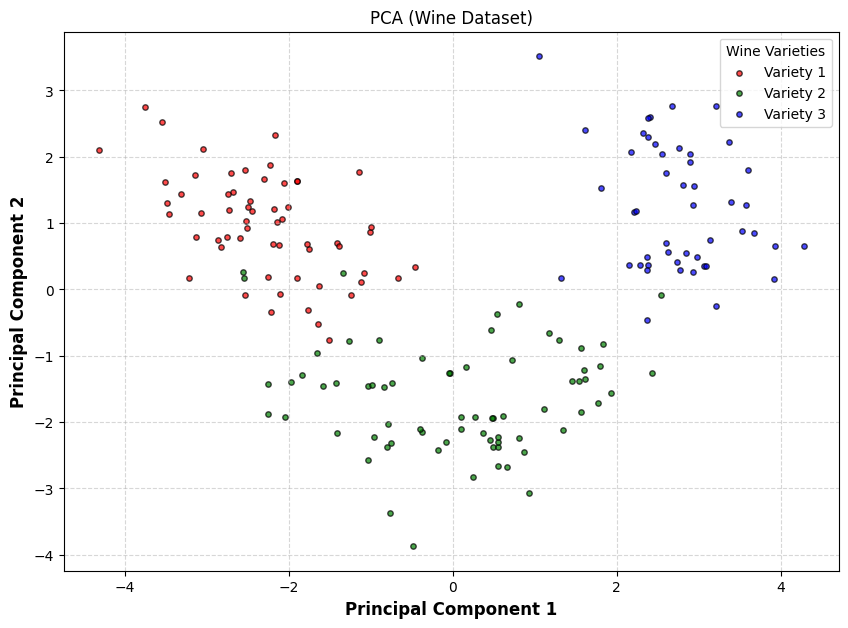

Shape of X: (178, 13), Shape of U: (13, 13), Shape of Lambdas: (13,)

--- Statistics ---
Total Variance: 13.00
Kept Variance: 7.20
Info %: 55.41%


In [5]:
# ==========================================
# ΜΕΡΟΣ 2: MAIN SCRIPT (ΕΚΤΕΛΕΣΗ)
# ==========================================

# 1. Φόρτωση Δεδομένων
data = load_wine()
X_raw = data.data
y = data.target

# 2. Προεπεξεργασία (Standardization)
# ΣΗΜΑΝΤΙΚΟ: Τα features στο κρασί έχουν διαφορετικές κλίμακες.
# Χρησιμοποιούμε StandardScaler πριν το PCA.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 3. Εφαρμογή PCA
M = 2  # Μείωση σε 2 διαστάσεις
Z, U, Lambdas, mu = pca_classic(X_scaled, M)

# 4. Οπτικοποίηση (Plotting) με Custom Labels
plt.figure(figsize=(10, 7))

# Ορίζουμε τα χρώματα και τα ονόματα που θέλουμε να φαίνονται
x_axis_name = "Principal Component 1"  # Αντί για σκέτο PC1
y_axis_name = "Principal Component 2"         # Αντί για σκέτο PC2
colors = ['red', 'green', 'blue']
custom_labels = ['Variety 1', 'Variety 2', 'Variety 3'] 

# Loop για κάθε κλάση ξεχωριστά
for i in range(len(custom_labels)):
    # Βρίσκουμε ποιες εγγραφές ανήκουν στην κλάση i
    indices = y == i
    
    # Σχεδιάζουμε τα σημεία
    plt.scatter(Z[indices, 0], Z[indices, 1],
                color=colors[i], 
                label=custom_labels[i], 
                alpha=0.7, 
                edgecolors='k',
                s=15) # s=μέγεθος κουκκίδας

plt.title('PCA (Wine Dataset)')
plt.xlabel(x_axis_name, fontsize=12, fontweight='bold')
plt.ylabel(y_axis_name, fontsize=12, fontweight='bold')
plt.legend(title="Wine Varieties", loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. Υπολογισμός Πληροφορίας που Διατηρήθηκε
# Για να δούμε το ποσοστό, τρέχουμε μια φορά το PCA με ΟΛΑ τα components
_, _, all_vals, _ = pca_classic(X_scaled, X_scaled.shape[1]) 
total_variance = np.sum(all_vals)
kept_variance = np.sum(Lambdas)

print(f"\n--- Statistics ---")
print(f"Total Variance: {total_variance:.2f}")
print(f"Kept Variance: {kept_variance:.2f}")
print(f"Info %: {(kept_variance / total_variance) * 100:.2f}%")

In [12]:
# --- ΚΩΔΙΚΑΣ ΕΡΜΗΝΕΙΑΣ (Τρέξε το αφού έχεις τρέξει το PCA) ---

# Το U περιέχει τα ιδιοδιανύσματα (Features x Components)
# U[:, 0] είναι τα βάρη για το PC1
# U[:, 1] είναι τα βάρη για το PC2

features = data.feature_names
pc1_loadings = U[:, 0]
pc2_loadings = U[:, 1]

# Φτιάχνουμε ένα DataFrame για να τα βλέπουμε ωραία
import pandas as pd
loadings_df = pd.DataFrame({
    'Feature': features,
    'PC1 Weight': pc1_loadings,
    'PC2 Weight': pc2_loadings,
    'PC1 Abs': np.abs(pc1_loadings) # Απόλυτη τιμή για να βρούμε τη σημασία
})

# Ταξινομούμε με βάση το ποιο επηρεάζει πιο πολύ το PC1
print("\n--- PC1 ---")
print(loadings_df.sort_values(by='PC1 Abs', ascending=False)[['Feature', 'PC1 Weight']].head(5))

# Ταξινομούμε με βάση το ποιο επηρεάζει πιο πολύ το PC2

loadings_df['PC2 Abs'] = np.abs(pc2_loadings)
print("\n--- PC2 ---")
print(loadings_df.sort_values(by='PC2 Abs', ascending=False)[['Feature', 'PC2 Weight']].head(5))


--- PC1 ---
                         Feature  PC1 Weight
6                     flavanoids   -0.422934
5                  total_phenols   -0.394661
11  od280/od315_of_diluted_wines   -0.376167
8                proanthocyanins   -0.313429
7           nonflavanoid_phenols    0.298533

--- PC2 ---
            Feature  PC2 Weight
9   color_intensity    0.529996
0           alcohol    0.483652
12          proline    0.364903
2               ash    0.316069
4         magnesium    0.299634
